# Phase 2A · 01 · Unified random forest

**Goal:** train the paper's unified CRC classifier, a random forest on all 27 studies, evaluated the way the paper's Methods describe, and compare its AUC with the paper's 0.84.

1. Cross-validation, and why it must keep each study whole.
2. Ten repeats of ten folds.
3. The random forest, with normalization learned on each training fold only.
4. AUC from the median over the ten repeats.

## Setup

Inputs come from notebook 1/03: raw shares of the paper's 347 genera for the 5,966 balanced samples, and the labels. Outputs go to `results/figures/phase_2/phase_2a/01_unified_random_forest/` and `results/tables/phase_2/phase_2a/01_unified_random_forest/`.

The two normalization functions are copied from notebook 1/03, so this notebook runs on its own.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold

SEED = 2000
PAPER_AUC = 0.84


def find_project_root() -> Path:
    """Walk up from the current folder to the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("No requirements.txt above this folder.")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
INPUTS = PROJECT_ROOT / "data" / "processed" / "phase_1" / "03_preprocessing"
FIGURES = PROJECT_ROOT / "results" / "figures" / "phase_2" / "phase_2a" / "01_unified_random_forest"
TABLES = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2a" / "01_unified_random_forest"
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))


PSEUDOCOUNT = 1e-5


def fit_log_std(relab: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Learn each genus's mean and spread (standard deviation + its 10th percentile) on the log scale."""
    logged = np.log10(relab + PSEUDOCOUNT)
    sd = logged.std(ddof=1)
    return logged.mean(), sd + np.quantile(sd, 0.1)


def apply_log_std(relab: pd.DataFrame, mean: pd.Series, spread: pd.Series) -> pd.DataFrame:
    """Log-transform and standardize with already learned numbers."""
    return (np.log10(relab + PSEUDOCOUNT) - mean) / spread

In [2]:
relab = pd.read_csv(INPUTS / "relab_347.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
labels = pd.read_csv(INPUTS / "labels.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
assert relab.index.equals(labels.index), "features and labels must be in the same row order"

y = labels["label"].to_numpy()
groups = labels["Cohort"].to_numpy()
print(f"{relab.shape[0]:,} samples, {relab.shape[1]} genera, CRC: {y.sum():,}, controls: {(y == 0).sum():,}, studies: {len(set(groups))}")

5,966 samples, 347 genera, CRC: 2,983, controls: 2,983, studies: 27


## 1. Cross-validation, and why it must keep each study whole

To measure how well a model works on data it has never seen, we hide part of the data during training and test on it afterwards. **K-fold cross-validation** does this systematically: split the samples into 10 parts (folds), train on 9 and test on the 10th, and repeat until every fold has been the test set once. Every sample then gets one prediction from a model that never saw it.

Samples from the same study share measurement quirks. If a study's samples sat on both sides of a split, the model could recognize the study instead of the disease, and the score would look better than it is. That is **data leakage**. The paper's Methods block by study: *"samples from a study would either all be in the training or the testing set"*.

scikit-learn's `StratifiedGroupKFold` does this. *Group* keeps each study whole, and *stratified* keeps the CRC/control ratio similar across folds. A toy example with 6 samples from 3 studies and 3 folds:

In [3]:
toy_y = np.array([1, 0, 1, 0, 1, 0])
toy_groups = np.array(["study_A", "study_A", "study_B", "study_B", "study_C", "study_C"])
toy_splits = StratifiedGroupKFold(n_splits=3).split(np.zeros(6), toy_y, toy_groups)
for fold, (train_idx, test_idx) in enumerate(toy_splits, start=1):
    print(f"fold {fold}: train on {sorted(set(toy_groups[train_idx].tolist()))}, test on {sorted(set(toy_groups[test_idx].tolist()))}")

fold 1: train on ['study_B', 'study_C'], test on ['study_A']
fold 2: train on ['study_A', 'study_C'], test on ['study_B']
fold 3: train on ['study_A', 'study_B'], test on ['study_C']


## 2. Ten repeats of ten folds

How studies land in folds is random, and with only 27 studies one unlucky split can move the score. The paper repeats the 10-fold procedure 10 times with different random splits. That gives 100 trained models and 10 predictions per sample.

In [4]:
folds = []
for repeat in range(10):
    splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED + repeat)
    folds.append(list(splitter.split(np.zeros(len(y)), y, groups)))

train_sizes = [len(train_idx) for repeat in folds for train_idx, _ in repeat]
test_sizes = [len(test_idx) for repeat in folds for _, test_idx in repeat]
print(f"{len(test_sizes)} folds. Average train size {np.mean(train_sizes):,.0f} (paper: 5,369), average test size {np.mean(test_sizes):,.0f} (paper: 597)")

100 folds. Average train size 5,369 (paper: 5,369), average test size 597 (paper: 597)


The averages match the paper's Figure 3B by construction: every sample is tested once per repeat, so the average test fold is always 5,966 / 10. The single folds are very uneven, because whole studies of very different sizes are dealt into them.

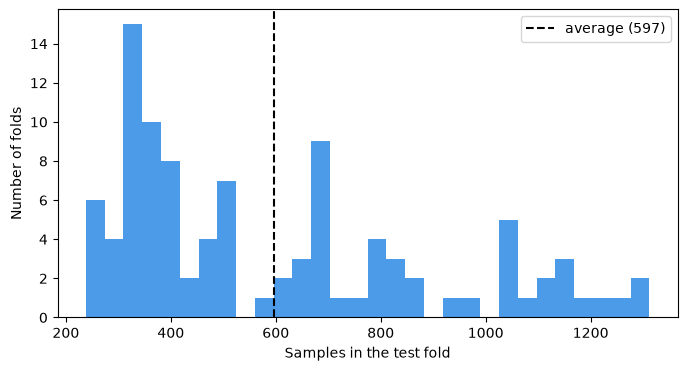

**Figure 1.** Across the 100 study-blocked test folds, sizes range from 238 to 1,312 samples (average 597). A fold's size depends on which studies it receives: the largest study alone contributes 1,026 balanced samples.

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(test_sizes, bins=30, color="#4C9BE8")
ax.axvline(np.mean(test_sizes), color="black", linestyle="--", label=f"average ({np.mean(test_sizes):.0f})")
ax.set_xlabel("Samples in the test fold")
ax.set_ylabel("Number of folds")
ax.legend()

show_figure(
    fig,
    "fold_sizes",
    f"Across the {len(test_sizes)} study-blocked test folds, sizes range from {min(test_sizes)} to {max(test_sizes):,} samples "
    f"(average {np.mean(test_sizes):.0f}). A fold's size depends on which studies it receives: the largest study alone "
    f"contributes {pd.Series(groups).value_counts().max():,} balanced samples.",
)

## 3. The model: a random forest

A random forest is a vote of many decision trees. Each tree trains on a random resample of the training data and, at every split, may choose only among a random subset of the features. That randomness makes the trees disagree in useful ways, and their average is more reliable than any single tree. The share of trees voting "CRC" is the predicted probability.

Settings: 200 trees and √(number of features) candidate features per split, √347 ≈ 18. The paper's text names a random forest (the R library `ranger`) but not these two numbers, so they are taken from the authors' code.

Inside every fold, normalization is **fitted on the training samples only**, then applied to the test samples with those frozen numbers. That is how the paper describes it: test samples are *"normalized using frozen parameters learned during model training"*.

In [6]:
def train_and_predict(relab: pd.DataFrame, y: np.ndarray, train_idx: np.ndarray, test_idx: np.ndarray) -> np.ndarray:
    """Fit normalization and forest on the training samples, return CRC probabilities for the test samples."""
    train, test = relab.iloc[train_idx], relab.iloc[test_idx]
    mean, spread = fit_log_std(train)
    forest = RandomForestClassifier(n_estimators=200, max_features="sqrt", n_jobs=-1, random_state=SEED)
    forest.fit(apply_log_std(train, mean, spread), y[train_idx])
    return forest.predict_proba(apply_log_std(test, mean, spread))[:, 1]


start = time.perf_counter()
predictions = np.full((len(y), len(folds)), np.nan)
for repeat, repeat_folds in enumerate(folds):
    for train_idx, test_idx in repeat_folds:
        predictions[test_idx, repeat] = train_and_predict(relab, y, train_idx, test_idx)
print(f"Trained {len(test_sizes)} forests in {time.perf_counter() - start:.0f} s")

Trained 100 forests in 131 s


## 4. AUC

Each sample now has 10 predicted probabilities, one per repeat. The paper's Methods combine them with the **median**.

**AUC** (area under the ROC curve) answers one question: pick one random CRC sample and one random control, how often does the CRC sample get the higher score? 0.5 is a coin flip and 1.0 is perfect. The ROC curve shows the trade-off behind it. Lowering the threshold for calling a sample "CRC" catches more cancers (true positive rate) but also flags more healthy people (false positive rate).

In [7]:
median_prediction = np.median(predictions, axis=1)
auc = roc_auc_score(y, median_prediction)
auc_per_repeat = [roc_auc_score(y, predictions[:, repeat]) for repeat in range(predictions.shape[1])]

pd.DataFrame([{"evaluation": "study-blocked 10x10 CV, median", "auc": round(auc, 4), "paper_auc": PAPER_AUC}]).to_csv(
    TABLES / "unified_auc.csv", index=False
)
print(f"AUC (median over repeats): {auc:.3f}   paper: {PAPER_AUC}")
print(f"AUC of the single repeats: {min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}")

AUC (median over repeats): 0.808   paper: 0.84
AUC of the single repeats: 0.802 to 0.807


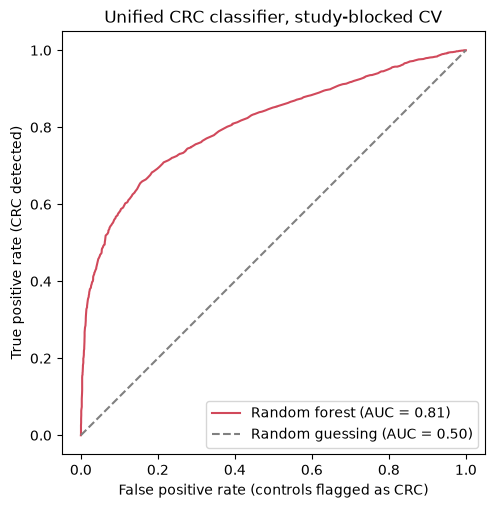

**Figure 2.** ROC curve of the median predictions for 5,966 samples (2,983 CRC, 2,983 controls). AUC = 0.808, against 0.84 in the paper (difference -0.032). The 10 single repeats range from 0.802 to 0.807. At a 10% false positive rate the model detects 58% of CRC samples.

In [8]:
false_positive_rate, true_positive_rate, _ = roc_curve(y, median_prediction)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(false_positive_rate, true_positive_rate, color="#D1495B", label=f"Random forest (AUC = {auc:.2f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing (AUC = 0.50)")
ax.set_xlabel("False positive rate (controls flagged as CRC)")
ax.set_ylabel("True positive rate (CRC detected)")
ax.set_title("Unified CRC classifier, study-blocked CV")
ax.legend(loc="lower right")
ax.set_aspect("equal")

detected_at_10_percent = true_positive_rate[np.searchsorted(false_positive_rate, 0.10, side="right") - 1]
show_figure(
    fig,
    "roc_unified",
    f"ROC curve of the median predictions for {len(y):,} samples (2,983 CRC, 2,983 controls). AUC = {auc:.3f}, "
    f"against {PAPER_AUC} in the paper (difference {auc - PAPER_AUC:+.3f}). The 10 single repeats range from "
    f"{min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}. At a 10% false positive rate the model detects "
    f"{detected_at_10_percent:.0%} of CRC samples.",
)

## 5. Checks

In [9]:
for repeat in folds:
    for train_idx, test_idx in repeat:
        assert set(groups[train_idx]).isdisjoint(groups[test_idx]), "no study on both sides of a split"
        assert set(y[test_idx]) == {0, 1}
assert predictions.shape == (5966, 10)
assert not np.isnan(predictions).any(), "every sample is tested once per repeat"
assert 0.5 < auc < 1
print("All checks passed.")

All checks passed.


## What we learned

- Study-blocked 10×10 cross-validation keeps every study whole, so each prediction comes from a model that never saw that sample's study. The average fold sizes, 5,369 for training and 597 for testing, match the paper's Figure 3B.
- Normalization is learned on the training folds only and applied frozen to the test fold, as the paper describes.
- The unified random forest reaches an AUC of **0.808**, against the paper's 0.84 (Figure 3B), a difference of 0.032.
- The single repeats lie between 0.802 and 0.807, so the result doesn't depend on one lucky split.
- At a 10% false positive rate the model detects 58% of CRC samples.